In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


# 01 — Exploratory Data Analysis

This notebook explores the NLR Generative AI Workload Power Profiles Dataset before model development.

The analysis focuses on:
- understanding the ZIP archive and workload organization
- reviewing the dataset documentation
- inspecting the aggregated power profiles and metadata
- verifying the relationship between Parquet files and metadata
- identifying configuration variables that may help predict power consumption
- checking for incomplete or unusable executions
- defining the dataset and predictors for the modeling stage

The dataset contains five workload groups:
- Llama3 70B offline inference
- Llama3 70B online finite-rate inference
- Llama3 70B online rate-based inference
- Llama2 70B LoRA training
- Stable Diffusion training

For modeling, the aggregated Parquet files are used as the primary power profile source because they already contain the combined power measurements provided by the dataset.

## 1.1 Dataset Verification

In [ ]:
# Check that the dataset ZIP is available before starting the analysis.
from pathlib import Path
import zipfile
dataset_zip_path = Path("/content/dataset.zip")
if not dataset_zip_path.exists():
    raise FileNotFoundError(
        f"Dataset ZIP was not found at {dataset_zip_path}. "
        "Please upload dataset.zip to /content."
    )
print(f"Dataset found: {dataset_zip_path}")
print(f"File size: {dataset_zip_path.stat().st_size / (1024**3):.2f} GB")

Dataset found: /content/dataset.zip
File size: 1.00 GB


## 1.1 ZIP Structure

First, we inspect the archive without extracting the full 1 GB dataset.

This gives us an overview of the file types and directory structure while avoiding unnecessary disk usage and processing time.

In [ ]:
from collections import Counter
with zipfile.ZipFile(dataset_zip_path, "r") as zip_file:
    entries = [entry for entry in zip_file.infolist() if not entry.is_dir()]
extension_counts = Counter(
    Path(entry.filename).suffix.lower() or "[no extension]"
    for entry in entries
)
top_level_counts = Counter(
    entry.filename.split("/")[0]
    for entry in entries
)
print(f"Total files: {len(entries):,}")
print("\nFiles by extension:")
for extension, count in sorted(extension_counts.items()):
    print(f"  {extension}: {count:,}")
print("\nTop level directories:")
for folder, count in sorted(top_level_counts.items()):
    print(f"  {folder}: {count:,} files")

Total files: 3,148

Files by extension:
  .csv: 14
  .ipynb: 6
  .json: 7
  .log: 608
  .md: 1
  .parquet: 2,467
  .png: 19
  .py: 7
  .sample: 13
  .sh: 1
  .txt: 1
  [no extension]: 4

Top level directories:
  .activate.sh: 1 files
  .git: 17 files
  00_raw_datasets: 615 files
  01_aggregated_datasets: 2,476 files
  02_analysis_scripts: 16 files
  03_whole-facility_profiles: 21 files
  README.md: 1 files
  requirements.txt: 1 files


## 1.2 Workload Organization

The raw data is organized by workload type. We identify these directories to confirm the workload groups available for analysis.

In [ ]:
workload_dirs = sorted({
    entry.filename.split("/")[1]
    for entry in entries
    if entry.filename.startswith("00_raw_datasets/")
    and len(entry.filename.split("/")) >= 3
})
print(f"Raw workload directories: {len(workload_dirs)}")
for workload in workload_dirs:
    print(f" - {workload}")

Raw workload directories: 5
 - inference_offline_llama3_70b
 - inference_online_finite_llama3_70b
 - inference_online_rate_llama3_70b
 - training_llama2_70b_lora
 - training_stable_diffusion


## 1.3 Dataset Documentation

The dataset README is reviewed directly from the ZIP file.

This helps confirm how the raw measurements, aggregated power profiles, and workload groups are organized before we begin building the modeling dataset.

In [ ]:
with zipfile.ZipFile(dataset_zip_path, "r") as zip_file:
    readme_files = [
        name for name in zip_file.namelist()
        if name.lower().endswith(".md")
    ]
    if not readme_files:
        raise FileNotFoundError("No README Markdown file was found in the ZIP archive.")
    readme_name = readme_files[0]
    readme_text = zip_file.read(readme_name).decode("utf-8", errors="replace")
print(readme_text)

# GenAI Power Profiles Dataset

This repository contains datasets and analysis scripts related to power consumption profiles of generative AI (GenAI) workloads, including both training and inference workloads.

The first version of the dataset includes the following genAI workloads:

- Training or Fine-Tuning:
    - Llamma2 (LLM)
    - Stable Diffusion (Image Generation)
- Inference (Offline and Online)
    - Llamma3 (LLM)

The goal of this dataset is to support data center research in:

- Infrastructure planning  
- Power modeling  
- Energy-aware job scheduling  
- Load forecasting  
- Grid integration studies  

<!-- -------------- -->

## Citation

If you use this dataset, please cite the associated publication: 

> Vercellino et al., “Measurement of Generative AI Workload Power Profiles for Whole-Facility Data Center Infrastructure Planning,” [arXiv:2604.07345](https://arxiv.org/abs/2604.07345) (2026).
 
The original dataset is available via the NLR Data Catalog: https://data.nlr.

## 1.4 Aggregated Power Profiles

The dataset provides aggregated Parquet files under the `01_aggregated_datasets` directory.

These files contain execution level power time series. We inspect one representative file from each workload group to verify the schema and sampling structure.

The training directory contains both Llama2 LoRA and Stable Diffusion executions, while the three inference directories contain the Llama3 inference workloads.

In [ ]:
import io
import pandas as pd
with zipfile.ZipFile(dataset_zip_path, "r") as zip_file:
    parquet_files = sorted(
        name for name in zip_file.namelist()
        if name.lower().endswith(".parquet")
    )
    parquet_counts = Counter(
        path.split("/")[1]
        for path in parquet_files
    )
    print("Parquet files by workload:")
    for workload, count in sorted(parquet_counts.items()):
        print(f"  {workload}: {count:,}")
    # Select one representative Parquet file from each workload group.
    sample_files = {}
    for path in parquet_files:
        workload = path.split("/")[1]
        sample_files.setdefault(workload, path)
    for workload, path in sorted(sample_files.items()):
        with zip_file.open(path) as file:
            sample_df = pd.read_parquet(io.BytesIO(file.read()))
        print(f"WORKLOAD:{workload}")
        print(f"FILE:{Path(path).name}")
        print(f"Rows:{len(sample_df):,}")
        print(f"Columns:{list(sample_df.columns)}")
        print(sample_df.head(3).to_string())

Parquet files by workload:
  inference_offline_llama3_70b: 1,200
  inference_online_finite_llama3_70b: 1,026
  inference_online_rate_llama3_70b: 200
  training: 41
WORKLOAD:inference_offline_llama3_70b
FILE:000000.parquet
Rows:511
Columns:['power[W]']
                power[W]
timestep[s]             
0.0           792.143065
0.1           991.327360
0.2          1248.529331
WORKLOAD:inference_online_finite_llama3_70b
FILE:000000.parquet
Rows:1,190
Columns:['power[W]']
                power[W]
timestep[s]             
0.0           837.754307
0.1           973.837795
0.2          1072.616736
WORKLOAD:inference_online_rate_llama3_70b
FILE:000000.parquet
Rows:179,955
Columns:['power[W]']
                power[W]
timestep[s]             
0.000        2066.473043
0.001        2066.474635
0.002        2066.476227
WORKLOAD:training
FILE:000000.parquet
Rows:26,601
Columns:['power[W]']
               power[W]
timestep[s]            
0.0          868.775478
0.2          875.796679
0.4          8

## 1.5 JSON Metadata

The JSON files contain workload configuration and execution information.

Some online finite metadata also contains vLLM performance measurements such as throughput and latency. These values describe the execution after or during the run, so they will not be used as predictors for power consumption because doing so could introduce target leakage.

In [ ]:
import json
with zipfile.ZipFile(dataset_zip_path, "r") as zip_file:
    json_files = sorted(
        name for name in zip_file.namelist()
        if name.lower().endswith(".json")
    )
    print(f"JSON files found: {len(json_files)}")
    for name in json_files:
        print(name)
        try:
            data = json.loads(
                zip_file.read(name).decode("utf-8")
            )
        except json.JSONDecodeError:
            print("Non-standard JSON/JSONL format; skipped for this inspection.")
            continue
        if isinstance(data, dict) and "experiments" in data:
            experiments = data["experiments"]
            print(f"Experiments: {len(experiments)}")
            if experiments:
                print(json.dumps(experiments[0], indent=2))
        elif isinstance(data, list):
            print(f"Records: {len(data)}")
            if data:
                print(f"Fields: {list(data[0].keys())}")
                print(json.dumps(data[0], indent=2))
        else:
            print(json.dumps(data, indent=2))

JSON files found: 7
00_raw_datasets/inference_offline_llama3_70b/config.json
{
  "SLURM_CPUS_ON_NODE": "128",
  "SLURM_GPUS_ON_NODE": "4",
  "SLURM_NODELIST": "x3115c0s33b0n0",
  "model": "/projects/aiuserapps/jwillard/hf_models/Llama-3.1-70B-Instruct"
}
00_raw_datasets/inference_offline_llama3_70b/log.json
Records: 1200
Fields: ['batch_size', 'elapsed', 'end_time', 'max_output_tokens', 'repeat', 'seed', 'start_time']
{
  "batch_size": 550,
  "elapsed": 51.138686,
  "end_time": "2025-09-18_16:31:03.916427",
  "max_output_tokens": 1024,
  "repeat": 0,
  "seed": 2854,
  "start_time": "2025-09-18_16:30:12.777741"
}
00_raw_datasets/inference_online_finite_llama3_70b/config.json
Experiments: 1026
{
  "_repeat": 0,
  "burstiness": 100000,
  "dataset-name": "hf",
  "dataset-path": "likaixin/InstructCoder",
  "hf-output-len": 256,
  "num-prompts": 1000,
  "request_rate": 10,
  "seed": 0
}
00_raw_datasets/inference_online_finite_llama3_70b/log.json
Records: 1026
Fields: ['_repeat', 'burstiness'

## 1.6 Parquet to Metadata Mapping

The number of Parquet files matches the number of metadata records for each inference workload.

The dataset's own postprocessing code saves the Parquet files using their position in the metadata records:

`NNNNNN.parquet` corresponds to the metadata record at the same position.

Therefore, the Parquet filename should be treated as a positional file identifier rather than assuming it is the experiment ID stored in the metadata.

In [ ]:
with zipfile.ZipFile(dataset_zip_path, "r") as zip_file:
    mapping_checks = {
        "inference_offline_llama3_70b":
            "00_raw_datasets/inference_offline_llama3_70b/log.json",

        "inference_online_finite_llama3_70b":
            "00_raw_datasets/inference_online_finite_llama3_70b/log.json",

        "inference_online_rate_llama3_70b":
            "00_raw_datasets/inference_online_rate_llama3_70b/log.json",
    }
    for workload, log_path in mapping_checks.items():
        log_records = json.loads(
            zip_file.read(log_path).decode("utf-8")
        )
        parquet_count = sum(
            1
            for path in parquet_files
            if f"01_aggregated_datasets/{workload}/results/" in path
        )
        status = "OK" if len(log_records) == parquet_count else "MISMATCH"
        print(
            f"{workload}: "
            f"metadata records={len(log_records):,}, "
            f"Parquet files={parquet_count:,} -> {status}"
        )

inference_offline_llama3_70b: metadata records=1,200, Parquet files=1,200 -> OK
inference_online_finite_llama3_70b: metadata records=1,026, Parquet files=1,026 -> OK
inference_online_rate_llama3_70b: metadata records=200, Parquet files=200 -> OK


## 1.7 Metadata Tables

The aggregated dataset also provides `metadata.csv` files containing execution level configuration and power summaries.

For the inference workloads, mean and peak power are already provided. The training metadata does not contain these power summaries, so they will be calculated from the corresponding Parquet profiles.

In [ ]:
metadata_paths = {
    "offline": "01_aggregated_datasets/inference_offline_llama3_70b/metadata.csv",
    "online_finite": "01_aggregated_datasets/inference_online_finite_llama3_70b/metadata.csv",
    "online_rate": "01_aggregated_datasets/inference_online_rate_llama3_70b/metadata.csv",
    "training": "01_aggregated_datasets/training/metadata.csv",
}
metadata = {}
with zipfile.ZipFile(dataset_zip_path, "r") as zip_file:
    for workload, path in metadata_paths.items():
        with zip_file.open(path) as file:
            metadata[workload] = pd.read_csv(file)
        print(f"{workload}:{metadata[workload].shape}")
        print(f"Columns:{list(metadata[workload].columns)}")
        display(metadata[workload].head(3))

offline:(1200, 10)
Columns:['batch_size', 'elapsed', 'end_time', 'max_output_tokens', 'repeat', 'seed', 'start_time', 'path_run', 'peak_power[W]', 'mean_power[W]']


,batch_size,elapsed,end_time,max_output_tokens,repeat,seed,start_time,path_run,peak_power[W],mean_power[W]
0,550,51.138686,2025-09-18 16:31:03.916427,1024,0,2854,2025-09-18 16:30:12.777741,/projects/aiuserapps/genai_power_dataset/01_ag...,3053.759065,2822.104293
1,550,47.384165,2025-09-18 16:31:53.300838,1024,1,2854,2025-09-18 16:31:05.916673,/projects/aiuserapps/genai_power_dataset/01_ag...,3048.839824,2814.350863
2,550,48.965850,2025-09-18 16:32:44.266972,1024,2,2854,2025-09-18 16:31:55.301122,/projects/aiuserapps/genai_power_dataset/01_ag...,3042.525523,2798.014121


online_finite:(1026, 72)
Columns:['_repeat', 'burstiness_x', 'dataset-name', 'dataset-path', 'end_time_exc', 'hf-output-len', 'id', 'num-prompts', 'request_rate_x', 'seed', 'start_time_exc', 'date', 'endpoint_type', 'backend', 'label', 'model_id', 'tokenizer_id', 'num_prompts', 'request_rate_y', 'burstiness_y', 'max_concurrency', 'duration', 'completed', 'total_input_tokens', 'total_output_tokens', 'request_throughput', 'request_goodput', 'output_throughput', 'total_token_throughput', 'max_output_tokens_per_s', 'max_concurrent_requests', 'mean_ttft_ms', 'median_ttft_ms', 'std_ttft_ms', 'p10_ttft_ms', 'p30_ttft_ms', 'p50_ttft_ms', 'p70_ttft_ms', 'p90_ttft_ms', 'mean_tpot_ms', 'median_tpot_ms', 'std_tpot_ms', 'p10_tpot_ms', 'p30_tpot_ms', 'p50_tpot_ms', 'p70_tpot_ms', 'p90_tpot_ms', 'mean_itl_ms', 'median_itl_ms', 'std_itl_ms', 'p10_itl_ms', 'p30_itl_ms', 'p50_itl_ms', 'p70_itl_ms', 'p90_itl_ms', 'mean_e2el_ms', 'median_e2el_ms', 'std_e2el_ms', 'p10_e2el_ms', 'p30_e2el_ms', 'p50_e2el_ms'

,_repeat,burstiness_x,dataset-name,dataset-path,end_time_exc,hf-output-len,id,num-prompts,request_rate_x,seed,...,p90_e2el_ms,start_time_vllm,end_time_vllm,start_time,end_time,run_completed,execution_time_seconds,path_run,peak_power[W],mean_power[W]
0,0,100000,hf,likaixin/InstructCoder,2025-11-30 15:41:52.015074,256,1,1000,10,0,...,5114.628401,2025-11-30 15:41:38,2025-11-30 15:43:22.123269388,2025-11-30 15:39:40.303018,2025-11-30 15:41:52.015074,True,118.9,/projects/aiuserapps/genai_power_dataset/01_ag...,2351.683114,2085.306406
1,0,100000,hf,likaixin/InstructCoder,2025-11-30 15:43:18.318080,256,2,1000,20,0,...,5457.068536,2025-11-30 15:43:18,2025-11-30 15:44:12.522184050,2025-11-30 15:42:12.017302,2025-11-30 15:43:18.318080,True,56.0,/projects/aiuserapps/genai_power_dataset/01_ag...,2348.551505,2265.948935
2,0,100000,hf,likaixin/InstructCoder,2025-11-30 15:44:27.872271,256,3,1000,30,0,...,5892.459001,2025-11-30 15:44:27,2025-11-30 15:45:05.159787518,2025-11-30 15:43:38.320088,2025-11-30 15:44:27.872271,True,39.6,/projects/aiuserapps/genai_power_dataset/01_ag...,2601.319313,2446.739765


online_rate:(200, 15)
Columns:['burstiness', 'dataset-name', 'dataset-path', 'end_time_exc', 'id', 'num-prompts', 'request_rate', 'start_time_exc', 'start_time', 'end_time', 'run_completed', 'execution_time_seconds', 'path_run', 'peak_power[W]', 'mean_power[W]']


,burstiness,dataset-name,dataset-path,end_time_exc,id,num-prompts,request_rate,start_time_exc,start_time,end_time,run_completed,execution_time_seconds,path_run,peak_power[W],mean_power[W]
0,100000,hf,likaixin/InstructCoder,2026-01-05 05:34:32.714319,1,300,1,2026-01-05 05:31:32.714319,2026-01-05 05:31:32.714319,2026-01-05 05:34:32.714319,True,179.954,/projects/aiuserapps/genai_power_dataset/01_ag...,2097.831345,2069.548985
1,100000,hf,likaixin/InstructCoder,2026-01-05 05:39:52.753836,2,600,2,2026-01-05 05:36:52.753836,2026-01-05 05:36:52.753836,2026-01-05 05:39:52.753836,True,179.846,/projects/aiuserapps/genai_power_dataset/01_ag...,2118.523541,2085.325478
2,100000,hf,likaixin/InstructCoder,2026-01-05 05:45:12.801867,3,900,3,2026-01-05 05:42:12.801867,2026-01-05 05:42:12.801867,2026-01-05 05:45:12.801867,True,179.943,/projects/aiuserapps/genai_power_dataset/01_ag...,2140.690436,2088.905829


training:(41, 6)
Columns:['Unnamed: 0', 'model', 'nodes', 'repeat', 'path_save', 'slurmid']


,Unnamed: 0,model,nodes,repeat,path_save,slurmid
0,0,llama2_70b_lora,2,0,training/results/000000.parquet,10742795
1,1,llama2_70b_lora,2,1,training/results/000001.parquet,10742796
2,2,llama2_70b_lora,2,2,training/results/000002.parquet,10742797


## 1.8 Training Power Summaries

Training has only 41 executions, and its `metadata.csv` does not contain mean or peak power.

We calculate these values from the corresponding aggregated Parquet profiles. The positional mapping established above is used to associate each power profile with its metadata record.

In [ ]:
training_power_rows = []
with zipfile.ZipFile(dataset_zip_path, "r") as zip_file:
    training_parquet_files = sorted(
        name
        for name in zip_file.namelist()
        if name.startswith("01_aggregated_datasets/training/results/")
        and name.lower().endswith(".parquet")
    )
    for metadata_index, path in enumerate(training_parquet_files):
        with zip_file.open(path) as file:
            power_values = pd.read_parquet(
                io.BytesIO(file.read())
            )["power[W]"]
        training_power_rows.append({
            "metadata_index": metadata_index,
            "mean_power[W]": power_values.mean(),
            "peak_power[W]": power_values.max(),
            "power_samples": len(power_values),
        })
training_power = pd.DataFrame(training_power_rows)
training_metadata = metadata["training"].reset_index(drop=True).copy()
training_metadata["metadata_index"] = training_metadata.index
training_full = (
    training_metadata
    .merge(training_power, on="metadata_index", how="left")
    .drop(columns="metadata_index")
)
assert training_full[
    ["mean_power[W]", "peak_power[W]"]
].notna().all().all()
print(
    f"Training executions: {len(training_full):,} "
    "| Missing power summaries: "
    f"{training_full[['mean_power[W]', 'peak_power[W]']].isna().sum().sum()}"
)
display(training_full.head())

Training executions: 41 | Missing power summaries: 0


,Unnamed: 0,model,nodes,repeat,path_save,slurmid,mean_power[W],peak_power[W],power_samples
0,0,llama2_70b_lora,2,0,training/results/000000.parquet,10742795,5267.813212,6144.482505,26601
1,1,llama2_70b_lora,2,1,training/results/000001.parquet,10742796,5284.503512,6124.141955,29169
2,2,llama2_70b_lora,2,2,training/results/000002.parquet,10742797,5278.125021,6115.386270,26562
3,3,llama2_70b_lora,2,3,training/results/000003.parquet,10742798,5226.846200,6115.803822,26595
4,4,llama2_70b_lora,2,4,training/results/000004.parquet,10742800,5259.117817,6143.958648,26567


## 1.9 Raw Measurement Format
The raw WattAMeter files are inspected only to understand the original measurement format.
- `nvml` files contain GPU measurements, including power and temperature.
- `rapl` files contain CPU socket/core energy and power measurements.
- The aggregated Parquet files already provide the combined power profiles needed for this project.
Because the aggregated files are the dataset provided modeling source, the raw logs do not need to be fully reprocessed here.

In [ ]:
raw_sample_paths = [
    "00_raw_datasets/inference_offline_llama3_70b/"
    "nvml_wattameter_x3115c0s33b0n0.log",
    "00_raw_datasets/inference_offline_llama3_70b/"
    "rapl_wattameter_x3115c0s33b0n0.log",
]
with zipfile.ZipFile(dataset_zip_path, "r") as zip_file:
    for path in raw_sample_paths:
        print(path)
        with zip_file.open(path) as file:
            for _ in range(3):
                line = file.readline().decode(
                    "utf-8",
                    errors="replace"
                ).strip()
                print(line[:160])

00_raw_datasets/inference_offline_llama3_70b/nvml_wattameter_x3115c0s33b0n0.log
# 2025-09-18_16:22:44.314867 - Power data for run 10720618
# 2025-09-18_16:22:44.314867 - Tracking started
# timestamp                  reading-time[ns] gpu-0[mW] gpu-1[mW] gpu-2[mW] gpu-3[mW] gpu-0[C] gpu-1[C] gpu-2[C] gpu-3[C]
00_raw_datasets/inference_offline_llama3_70b/rapl_wattameter_x3115c0s33b0n0.log
# 2025-09-18_16:22:44.314867 - Power data for run 10720618
# 2025-09-18_16:22:44.314867 - Tracking started
# timestamp                  reading-time[ns] cpu-0[uJ] cpu-0-core[uJ] cpu-1[uJ] cpu-1-core[uJ] cpu-0[W] cpu-0-core[W] cpu-1[W] cpu-1-core[W]


## 1.10 Execution Counts and Configuration Variation

Next, we examine which metadata fields actually vary between executions.

Power measurements and other execution outcomes are excluded from this comparison because they should not be used as input features for the prediction model.

In [ ]:
excluded_fields = {
    "mean_power[W]",
    "peak_power[W]",
    "elapsed",
    "execution_time_seconds",
    "path_run",
    "path_save",
    "slurmid",
    "id",
    "Unnamed: 0",
    "start_time",
    "end_time",
    "start_time_exc",
    "end_time_exc",
    "start_time_vllm",
    "end_time_vllm",
}
for workload in ["offline", "online_finite", "online_rate", "training"]:
    workload_df = (
        training_full
        if workload == "training"
        else metadata[workload]
    )
    varying_fields = [
        (column, workload_df[column].nunique(dropna=True))
        for column in workload_df.columns
        if column not in excluded_fields
        and workload_df[column].nunique(dropna=True) > 1
    ]
    print(f"{workload}: {len(workload_df):,} executions")
    if varying_fields:
        print("Varying configuration fields:")
        for column, unique_values in varying_fields:
            print(f"  {column}: {unique_values} unique values")
    else:
        print("No varying configuration fields found.")

offline: 1,200 executions
Varying configuration fields:
  batch_size: 40 unique values
  max_output_tokens: 2 unique values
  repeat: 3 unique values
  seed: 400 unique values
online_finite: 1,026 executions
Varying configuration fields:
  _repeat: 3 unique values
  dataset-path: 2 unique values
  hf-output-len: 3 unique values
  request_rate_x: 19 unique values
  seed: 3 unique values
  date: 1024 unique values
  request_rate_y: 19 unique values
  duration: 1024 unique values
  total_input_tokens: 6 unique values
  total_output_tokens: 993 unique values
  request_throughput: 1024 unique values
  output_throughput: 1024 unique values
  total_token_throughput: 1024 unique values
  max_output_tokens_per_s: 810 unique values
  max_concurrent_requests: 356 unique values
  mean_ttft_ms: 1024 unique values
  median_ttft_ms: 1024 unique values
  std_ttft_ms: 1024 unique values
  p10_ttft_ms: 1024 unique values
  p30_ttft_ms: 1024 unique values
  p50_ttft_ms: 1024 unique values
  p70_ttft_ms: 

## 1.11 Configuration and Mean Power

The exploratory results show that several workload configuration variables have a relationship with mean power.

- **Offline inference:** power increases substantially as `batch_size` increases, with the relationship becoming less linear at larger batch sizes.
- **Online-rate inference:** power generally increases with `request_rate` before reaching a plateau.
- **Online-finite inference:** power increases with request rate at lower rates and then becomes relatively stable.
- **Training:** only 41 executions are available, so training is kept separate from the primary inference modeling dataset.

These relationships support using workload configuration as input to the power prediction model.

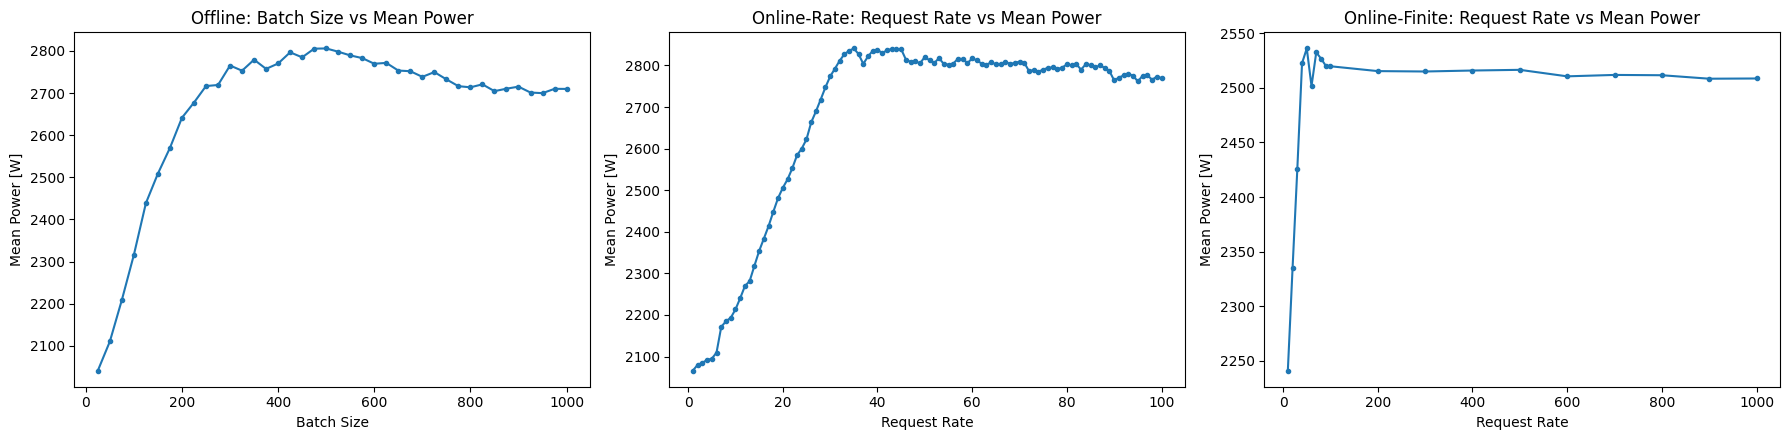

In [ ]:
import matplotlib.pyplot as plt
offline_power = (
    metadata["offline"]
    .groupby("batch_size")["mean_power[W]"]
    .mean()
)
online_rate_power = (
    metadata["online_rate"]
    .groupby("request_rate")["mean_power[W]"]
    .mean()
)
online_finite_power = (
    metadata["online_finite"]
    .groupby("request_rate_x")["mean_power[W]"]
    .mean()
)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].plot(
    offline_power.index,
    offline_power.values,
    marker="o",
    markersize=3
)
axes[0].set_title("Offline: Batch Size vs Mean Power")
axes[0].set_xlabel("Batch Size")
axes[0].set_ylabel("Mean Power [W]")
axes[1].plot(
    online_rate_power.index,
    online_rate_power.values,
    marker="o",
    markersize=3
)
axes[1].set_title("Online-Rate: Request Rate vs Mean Power")
axes[1].set_xlabel("Request Rate")
axes[1].set_ylabel("Mean Power [W]")
axes[2].plot(
    online_finite_power.index,
    online_finite_power.values,
    marker="o",
    markersize=3
)
axes[2].set_title("Online-Finite: Request Rate vs Mean Power")
axes[2].set_xlabel("Request Rate")
axes[2].set_ylabel("Mean Power [W]")
plt.tight_layout()
plt.show()

## 1.12 Data Quality: Incomplete Executions
Two online finite executions have unusually low mean power values of approximately 740 W.

Both records are marked as incomplete with `run_completed == False`. These runs do not represent normal completed workload executions, so they are excluded from the primary modeling dataset.

This exclusion is based on the recorded completion status rather than simply removing statistical outliers.

In [ ]:
online_finite_df = metadata["online_finite"]
low_power_runs = online_finite_df[
    online_finite_df["mean_power[W]"] < 1000
]
display_columns = [
    column
    for column in [
        "id",
        "request_rate_x",
        "hf-output-len",
        "dataset-path",
        "duration",
        "completed",
        "run_completed",
        "mean_power[W]",
    ]
    if column in low_power_runs.columns
]
print(f"Low-power executions identified: {len(low_power_runs)}")
display(low_power_runs[display_columns])
print("\nCompletion status where available:")
for workload in [
    "offline",
    "online_finite",
    "online_rate",
    "training",
]:
    workload_df = (
        training_full
        if workload == "training"
        else metadata[workload]
    )
    if "run_completed" in workload_df.columns:
        print(
            f"  {workload}: "
            f"{workload_df['run_completed'].value_counts().to_dict()}"
        )
    else:
        print(
            f"  {workload}: run_completed field not available "
            f"({len(workload_df):,} executions)"
        )

Low-power executions identified: 2


,id,request_rate_x,hf-output-len,dataset-path,duration,completed,run_completed,mean_power[W]
686,687,30,256,likaixin/InstructCoder,NaN,NaN,False,743.649697
708,709,60,256,mgoin/mlperf-inference-llama2-data,NaN,NaN,False,739.054963



Completion status where available:
  offline: run_completed field not available (1,200 executions)
  online_finite: {True: 1024, False: 2}
  online_rate: {True: 200}
  training: run_completed field not available (41 executions)


## 1.13 EDA Conclusions

The EDA supports the following modeling decisions:

1. Use the dataset provided aggregated Parquet profiles and metadata rather than reprocessing the raw device level logs.

2. Parquet files and metadata records are matched positionally, based on the dataset's own postprocessing workflow.

3. The primary modeling dataset will contain the three inference workloads:
   - offline inference
   - online finite rate inference
   - online rate based inference

4. There are 2,426 inference executions in total. Two incomplete online finite executions are removed, leaving **2,424 valid executions** for modeling.

5. The target variable is **mean power consumption (`mean_power[W]`)**.

6. Candidate predictors are:
   - `workload_type`
   - `batch_size`
   - `max_output_tokens`
   - `request_rate`
   - `output_length`
   - `dataset`

7. `num_prompts` is not used as a predictor because it is constant for online finite inference and is perfectly correlated with `request_rate` for online-rate inference.

8. Execution outcomes such as peak power, duration, throughput, latency, and completion status are excluded from the predictors to avoid data leakage.

9. Training is kept separate because only 41 training executions are available.

The next notebook will create a leakage safe preprocessing pipeline using the 2,424 valid inference executions.

→ Continue to **02_Preprocessing.ipynb**

In [ ]:
# Create a clean execution level dataset for the preprocessing notebook.
# Only valid inference executions and modeling variables are retained.
offline = metadata["offline"].copy()
offline["workload_type"] = "offline_inference"
offline_modeling = offline.rename(
    columns={
        "max_output_tokens": "max_output_tokens",
        "mean_power[W]": "mean_power_w",
    }
)[
    [
        "workload_type",
        "batch_size",
        "max_output_tokens",
        "mean_power_w",
    ]
]
online_finite = metadata["online_finite"].copy()
# Remove the two incomplete executions identified during EDA.
online_finite = online_finite[
    online_finite["run_completed"] == True
].copy()
online_finite["workload_type"] = "online_finite_inference"
online_finite_modeling = online_finite.rename(
    columns={
        "request_rate_x": "request_rate",
        "hf-output-len": "output_length",
        "dataset-path": "dataset",
        "mean_power[W]": "mean_power_w",
    }
)[
    [
        "workload_type",
        "request_rate",
        "output_length",
        "dataset",
        "mean_power_w",
    ]
]
online_rate = metadata["online_rate"].copy()
online_rate["workload_type"] = "online_rate_inference"
online_rate_modeling = online_rate.rename(
    columns={
        "request_rate": "request_rate",
        "dataset-path": "dataset",
        "mean_power[W]": "mean_power_w",
    }
)[
    [
        "workload_type",
        "request_rate",
        "dataset",
        "mean_power_w",
    ]
]
# Combine the three inference workload types.
modeling_dataset = pd.concat(
    [
        offline_modeling,
        online_finite_modeling,
        online_rate_modeling,
    ],
    ignore_index=True
)
print(f"Final modeling dataset shape: {modeling_dataset.shape}")
print("\nWorkload counts:")
print(modeling_dataset["workload_type"].value_counts())
print("\nMissing values:")
print(modeling_dataset.isna().sum())
display(modeling_dataset.head())

Final modeling dataset shape: (2424, 7)

Workload counts:
workload_type
offline_inference          1200
online_finite_inference    1024
online_rate_inference       200
Name: count, dtype: int64

Missing values:
workload_type           0
batch_size           1224
max_output_tokens    1224
mean_power_w            0
request_rate         1200
output_length        1400
dataset              1200
dtype: int64


,workload_type,batch_size,max_output_tokens,mean_power_w,request_rate,output_length,dataset
0,offline_inference,550.0,1024.0,2822.104293,NaN,NaN,NaN
1,offline_inference,550.0,1024.0,2814.350863,NaN,NaN,NaN
2,offline_inference,550.0,1024.0,2798.014121,NaN,NaN,NaN
3,offline_inference,275.0,1024.0,2694.764568,NaN,NaN,NaN
4,offline_inference,275.0,1024.0,2696.992151,NaN,NaN,NaN


## Modeling Dataset Handoff

The final execution level dataset contains **2,424 valid inference executions**.

Only variables that are available as workload/configuration information are retained for modeling. Execution outcomes and target-derived information have been excluded.

This dataset will be used as the input to `02_Preprocessing.ipynb`, where missing values, categorical variables, and numerical features will be handled using a leakage-safe preprocessing pipeline.

In [ ]:
# Save the clean modeling dataset to Google Drive.
# This keeps the dataset available even if the Colab runtime restarts.
from pathlib import Path
google_drive_processed_dir = Path(
    "/content/drive/MyDrive/data/processed"
)
google_drive_processed_dir.mkdir(
    parents=True,
    exist_ok=True
)
modeling_dataset_path = (
    google_drive_processed_dir / "inference_modeling_dataset.csv"
)
modeling_dataset.to_csv(
    modeling_dataset_path,
    index=False
)
print(f"Saved modeling dataset to: {modeling_dataset_path}")
print(f"Rows: {len(modeling_dataset):,}")
print(f"Columns: {len(modeling_dataset.columns)}")

Saved modeling dataset to: /content/drive/MyDrive/data/processed/inference_modeling_dataset.csv
Rows: 2,424
Columns: 7
